In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/processed/employees_clean.csv")

In [3]:
df.shape

(1470, 34)

In [4]:
df.groupby("OverTime")["AttritionFlag"].mean()

OverTime
No     0.104364
Yes    0.305288
Name: AttritionFlag, dtype: float64

In [5]:
(  df.groupby("OverTime")["AttritionFlag"].mean() * 100  ).round(2)

OverTime
No     10.44
Yes    30.53
Name: AttritionFlag, dtype: float64

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
taxa_overtime = ( df.groupby("OverTime")["AttritionFlag"].mean() * 100 ).round(2)

In [8]:
taxa_overtime

OverTime
No     10.44
Yes    30.53
Name: AttritionFlag, dtype: float64

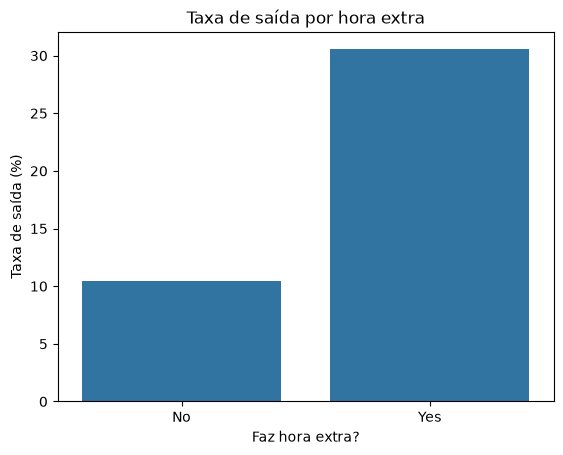

In [9]:
sns.barplot(x=taxa_overtime.index, y =taxa_overtime.values)
plt.ylabel("Taxa de saída (%)")
plt.title("Taxa de saída por hora extra")
plt.xlabel("Faz hora extra?")
plt.show()

Quem faz hora extra tem taxa de saída de 30,53%, contra 10,44% de quem não faz: quase 3 vezes maior. Os dados mostram a associação, mas não provam que a hora extra é a causa da saída

In [10]:
( df.groupby("JobRole")["AttritionFlag"].mean() * 100).round(2).sort_values(ascending=False)

JobRole
Sales Representative         39.76
Laboratory Technician        23.94
Human Resources              23.08
Sales Executive              17.48
Research Scientist           16.10
Manufacturing Director        6.90
Healthcare Representative     6.87
Manager                       4.90
Research Director             2.50
Name: AttritionFlag, dtype: float64

In [11]:
df["JobRole"].value_counts()

JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

O cargo com a maior taxa de saída é Sales Representative, com 39,76% (33 de 83 funcionários). A base é menor que a de outros cargos, mas a taxa é alta o bastante para merecer atenção. Os dados mostram a associação, mas não provam a causa da saída.

In [12]:
taxa_cargo = (df.groupby("JobRole")["AttritionFlag"].mean() * 100).round(2).sort_values(ascending=False)

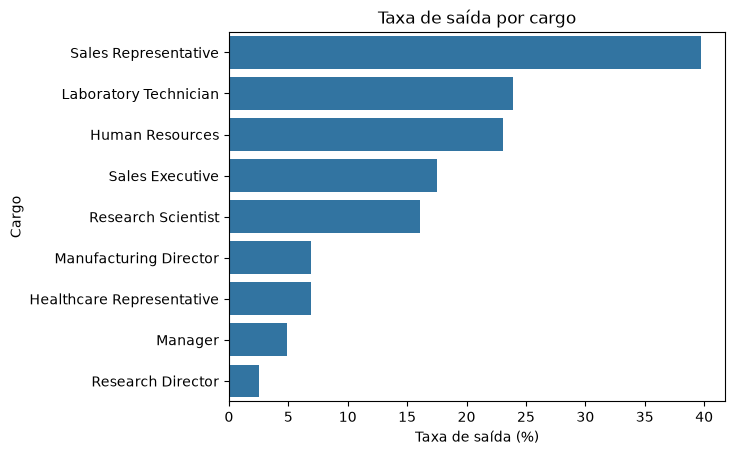

In [13]:
sns.barplot(x=taxa_cargo.values, y=taxa_cargo.index)
plt.ylabel("Cargo")
plt.title("Taxa de saída por cargo")
plt.xlabel("Taxa de saída (%)")
plt.show()

In [14]:
df["FaixaDistancia"] = pd.cut(df["DistanceFromHome"], bins=[0, 5, 15, 29], labels=["1-5", "6-15", "16-29"])

In [15]:
df["FaixaDistancia"].value_counts()

FaixaDistancia
1-5      632
6-15     509
16-29    329
Name: count, dtype: int64

In [16]:
taxa_distancia = (df.groupby("FaixaDistancia")["AttritionFlag"].mean() * 100).round(2)

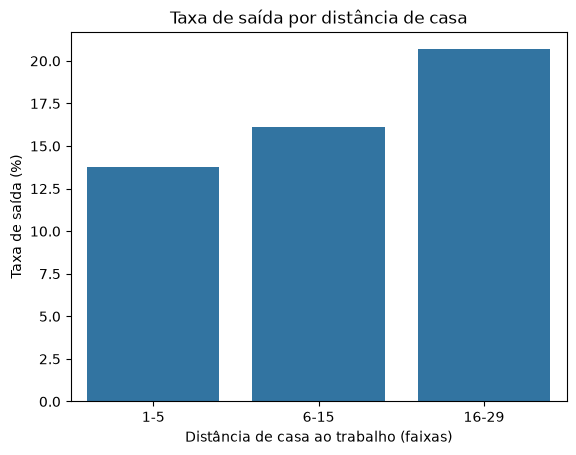

In [17]:
sns.barplot(x=taxa_distancia.index, y=taxa_distancia.values)
plt.title("Taxa de saída por distância de casa")
plt.xlabel("Distância de casa ao trabalho (faixas)")
plt.ylabel("Taxa de saída (%)")
plt.show()

Quem mora na faixa mais distante (16-29) tem taxa de saída de 20,67%, contra 13,77% de quem mora na faixa mais próxima (1-5): cerca de 1,5 vez maior. É um efeito mais fraco que o da hora extra. Os dados mostram a associação, mas não provam que a distância é a causa da saída.

In [18]:
df.groupby("Attrition")["MonthlyIncome"].mean().round(2)

Attrition
No     6832.74
Yes    4787.09
Name: MonthlyIncome, dtype: float64

In [19]:
df.groupby("Attrition")["JobSatisfaction"].mean().round(2)

Attrition
No     2.78
Yes    2.47
Name: JobSatisfaction, dtype: float64

Quem saiu ganhava em média 4.787,09 por mês, contra 6.832,74 de quem ficou (cerca de 30% a menos). A satisfação média também foi menor, 2,47 contra 2,78, mas a diferença é pequena numa escala de 1 a 4. Os dados mostram a associação, mas não provam a causa da saída.